# 5) Randles Circuit Simulation

This notebook simulates the impedance of a series RC circuit:
$$
Z = R_s + 1 / (1/R_{ct} + j * omega * C_{dl})
$$

Goals:
- Generate a frequency vector
- Compute real/imag/magnitude/phase
- Add Gaussian noise to both components
- Visualise Nyquist and Bode behaviour
- Export dataset to `data/simulated/`


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / "src").is_dir():
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from src.simulation.randles import simulate_randles

In [2]:
# Simulation Parameters
R_s = 10      # ohms
R_ct = 30      # ohms
C_dl = 1e-4    # 10 mF
f_min = 1
f_max = 1e10
num_points = 1000

frequencies = np.logspace(np.log10(f_min), np.log10(f_max), num_points)
noise_level = 0.1  # noise on both real and imaginary parts

Z = simulate_randles(R_s, R_ct, C_dl, frequencies, noise_level=noise_level)

real_Z = Z.real
imag_Z = Z.imag
mag_Z = np.abs(Z)
phase_Z = np.angle(Z)


# Visualisations

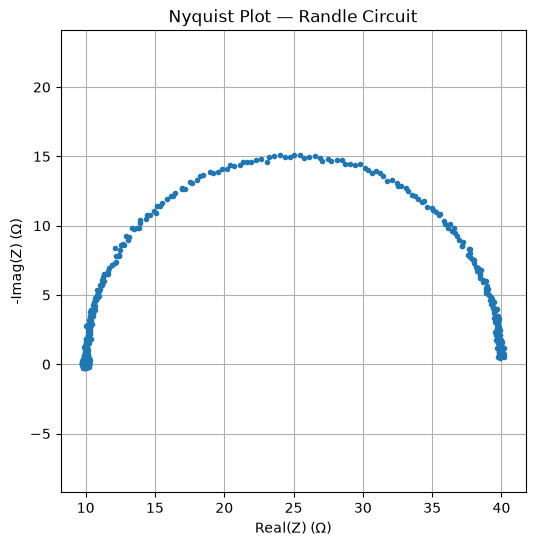

In [ ]:
# Nyquist Plot
plt.figure(figsize=(6,6))
plt.plot(real_Z, -imag_Z, 'o', markersize=3)
plt.title("Nyquist Plot — Randles Circuit")
plt.xlabel("Real(Z) (Ω)")
plt.ylabel("-Imag(Z) (Ω)")
plt.grid(True)
plt.axis('equal')
plt.show()


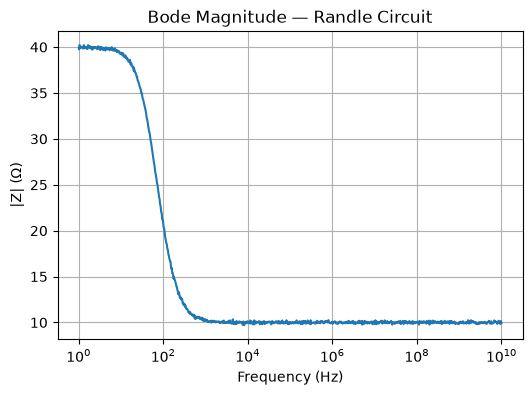

In [ ]:
# Bode Magnitude
plt.figure(figsize=(6,4))
plt.semilogx(frequencies, mag_Z)
plt.title("Bode Magnitude — Randles Circuit")
plt.xlabel("Frequency (Hz)")
plt.ylabel("|Z| (Ω)")
plt.grid(True)
plt.show()


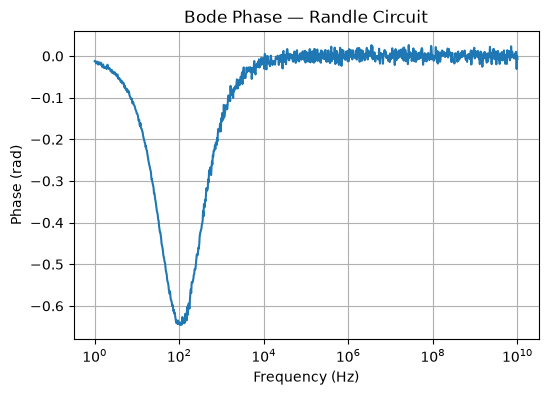

In [ ]:
# Bode Phase
plt.figure(figsize=(6,4))
plt.semilogx(frequencies, phase_Z)
plt.title("Bode Phase — Randles Circuit")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Phase (rad)")
plt.grid(True)
plt.show()


# Export Dataset

In [6]:
df = pd.DataFrame({
    "frequency": frequencies,
    "real": real_Z,
    "imag": imag_Z,
    "magnitude": mag_Z,
    "phase_rad": phase_Z
})

output_path = f"../data/simulated/randles_Rs{R_s}_Rct{R_ct}_C{C_dl*1e6:.0f}mF.csv"
df.to_csv(output_path, index=False)

output_path


'../data/simulated/randles_Rs10_Rct30_C100mF.csv'

# Summary

This notebook generated a simulated impedance dataset for a Randles circuit.
The dataset was saved in `data/simulated/randles_Rs100_Rct20_C10mF.csv`.